In [1]:
import pandas as pd
import matplotlib.pyplot  as plt
from metrics import metrics
from model import generics
from scipy.stats import wilcoxon
pd.set_option('display.max_rows', 2000)
pd.set_option('display.max_columns', 2000)
%load_ext autoreload
%autoreload 2

In [2]:
experiment_id = 'hourwindspeed'

In [3]:
df_mean_metrics, df_all_metrics, df_prevs = metrics.open_fold_result(experiment_id, normalize=False)

/home/domingosjr/experiments/src/metrics/metrics.py:347: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_metric = pd.DataFrame(all_metrics).fillna(-1).infer_objects(copy=False)
/home/domingosjr/experiments/src/metrics/metrics.py:347: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_metric = pd.DataFrame(all_metrics).fillna(-1).infer_objects(copy=False)
/home/domingosjr/experiments/src/metrics/metrics.py:347: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_obje

In [4]:
df_all_metrics[['horizonte', 'name']] = df_all_metrics['model'].str.extract(r'(\d+)(.+)')
extracted = df_mean_metrics.reset_index()['model'].str.extract(r'(\d+)(.+)')
df_mean_metrics[['horizonte', 'name']] = extracted.values


In [5]:
df_mean_metrics.head()

MSE      RMSE       MAPE  \
ts                         model                                              
windspeedcampinagrandehour 24arima            0.643935  0.802456  15.689360   
                           24combmean         0.594258  0.770877  14.744894   
                           24elm              0.624750  0.790363  15.338520   
                           24elmbagg100.50.5  0.613290  0.783046  15.362242   
                           24elmbagg100.50.8  0.605363  0.778040  15.207109   

                                                  SMAPE       MAE      theil  \
ts                         model                                               
windspeedcampinagrandehour 24arima            15.233836  0.606614   2.808974   
                           24combmean         14.652017  0.585192  16.891222   
                           24elm              15.100101  0.604254  10.029042   
                           24elmbagg100.50.5  14.899776  0.597968  19.622413   
                           24elmbagg100.50.8  14.840215  0.595056  19.994376   

                                                   ARV        IA      POCID  \
ts                         model                                              
windspeedcampinagrandehour 24arima            0.855038  0.769414  66.666667   
                           24combmean         1.545529  0.709498  65.171233   
                           24elm              1.601067  0.694974  60.821918   
                           24elmbagg100.50.5  1.586790  0.699867  63.070776   
                           24elmbagg100.50.8  1.656199  0.697679  63.025114   

                                              val_metric  time_testing  \
ts                         model                                         
windspeedcampinagrandehour 24arima                   inf     -1.000000   
                           24combmean                inf     -1.000000   
                           24elm                0.821170      0.000529   
                           24elmbagg100.50.5    0.818611      0.017444   
                           24elmbagg100.50.8    0.813060      0.023641   

                                              time_training horizonte  \
ts                         model                                        
windspeedcampinagrandehour 24arima                -1.000000        24   
                           24combmean             -1.000000        24   
                           24elm                   0.092600        24   
                           24elmbagg100.50.5       0.155017        24   
                           24elmbagg100.50.8       0.128526        24   

                                                         name  
ts                         model                               
windspeedcampinagrandehour 24arima                      arima  
                           24combmean                combmean  
                           24elm                          elm  
                           24elmbagg100.50.5  elmbagg100.50.5  
                           24elmbagg100.50.8  elmbagg100.50.8

In [7]:
# selection based on validation considering sufix
df_selected = pd.DataFrame()

sufix_modelos_to_agroup = [
    'elmbagg',
    'mlpbagg',
    'rf'
]

df_group = df_mean_metrics.reset_index().copy()

for sufix_atual in sufix_modelos_to_agroup:
    print('*' * 100)
    print(sufix_atual)
    filter_cond = df_group['model'].apply(
        lambda x: sufix_atual in x if pd.notna(x) else False
    )
    df_fitered = df_group[filter_cond].copy()
    
    display(df_fitered[['ts', 'horizonte']].value_counts())
    idx_min = df_fitered.groupby(["ts", 'horizonte'])["val_metric"].idxmin()
    resultado = df_fitered.loc[idx_min, ["ts", "model", "MSE", 'MAPE', 'MAE', 'horizonte', 'name']]
    resultado['sufix'] = sufix_atual
    df_selected = pd.concat([df_selected, resultado])

****************************************************************************************************
elmbagg


ts                           horizonte
windspeedcampinagrandehour   24           12
                             48           12
                             72           12
windspeedmaceiohour          24           12
                             48           12
                             72           12
windspeedsalvadorhour        24           12
                             48           12
                             72           12
windspeedcaruaruhour         24            1
                             48            1
                             72            1
windspeedcastelodopiauihour  24            1
                             48            1
                             72            1
Name: count, dtype: int64

****************************************************************************************************
mlpbagg


ts                           horizonte
windspeedcampinagrandehour   24           12
                             48           12
                             72           12
windspeedmaceiohour          24           12
                             48           12
                             72           12
windspeedsalvadorhour        24           12
                             48           12
                             72           12
windspeedcaruaruhour         24            1
                             48            1
                             72            1
windspeedcastelodopiauihour  24            1
                             48            1
                             72            1
Name: count, dtype: int64

****************************************************************************************************
rf


ts                          horizonte
windspeedcampinagrandehour  24           12
                            48           12
                            72           12
windspeedmaceiohour         24           12
                            48           12
                            72           12
windspeedsalvadorhour       24           12
                            48           12
                            72           12
Name: count, dtype: int64

In [8]:
df_selected

,ts,model,MSE,MAPE,MAE,horizonte,name,sufix
10,windspeedcampinagrandehour,24elmbagg300.80.8,0.601884,15.165523,0.593424,24,elmbagg300.80.8,elmbagg
59,windspeedcampinagrandehour,48elmbagg500.80.8,0.740458,16.594960,0.652778,48,elmbagg500.80.8,elmbagg
102,windspeedcampinagrandehour,72elmbagg500.50.8,0.812964,17.370424,0.679700,72,elmbagg500.50.8,elmbagg
138,windspeedcaruaruhour,24elmbagg500.80.8,0.455879,24.765776,0.529326,24,elmbagg500.80.8,elmbagg
149,windspeedcaruaruhour,48elmbagg500.80.8,0.506447,26.554922,0.565143,48,elmbagg500.80.8,elmbagg
160,windspeedcaruaruhour,72elmbagg500.80.8,0.531987,27.176072,0.578090,72,elmbagg500.80.8,elmbagg
171,windspeedcastelodopiauihour,24elmbagg500.80.8,0.707422,36.662741,0.683531,24,elmbagg500.80.8,elmbagg
182,windspeedcastelodopiauihour,48elmbagg500.80.8,0.759186,38.848157,0.704399,48,elmbagg500.80.8,elmbagg
193,windspeedcastelodopiauihour,72elmbagg500.80.8,0.759056,38.664248,0.694471,72,elmbagg500.80.8,elmbagg
215,windspeedmaceiohour,24elmbagg500.80.8,0.841165,39.265546,0.720644,24,elmbagg500.80.8,elmbagg


In [9]:
len([c for c in df_mean_metrics.reset_index()['model'].unique().tolist() if 'svrbagg1' in c])

0

In [10]:
df_mean_metrics.reset_index()['model'].unique()

array(['24arima', '24combmean', '24elm', '24elmbagg100.50.5',
       '24elmbagg100.50.8', '24elmbagg100.80.5', '24elmbagg100.80.8',
       '24elmbagg300.50.5', '24elmbagg300.50.8', '24elmbagg300.80.5',
       '24elmbagg300.80.8', '24elmbagg500.50.5', '24elmbagg500.50.8',
       '24elmbagg500.80.5', '24elmbagg500.80.8', '24kan', '24ma', '24mlp',
       '24mlpbagg100.50.5', '24mlpbagg100.50.8', '24mlpbagg100.80.5',
       '24mlpbagg100.80.8', '24mlpbagg300.50.5', '24mlpbagg300.50.8',
       '24mlpbagg300.80.5', '24mlpbagg300.80.8', '24mlpbagg500.50.5',
       '24mlpbagg500.50.8', '24mlpbagg500.80.5', '24mlpbagg500.80.8',
       '24nhits', '24rf100.50.5', '24rf100.50.8', '24rf100.80.5',
       '24rf100.80.8', '24rf300.50.5', '24rf300.50.8', '24rf300.80.5',
       '24rf300.80.8', '24rf500.50.5', '24rf500.50.8', '24rf500.80.5',
       '24rf500.80.8', '24svr', '24tcn', '48arima', '48combmean', '48elm',
       '48elmbagg100.50.5', '48elmbagg100.50.8', '48elmbagg100.80.5',
       '48elmbagg100

In [11]:
df_mean_metrics.columns

Index(['MSE', 'RMSE', 'MAPE', 'SMAPE', 'MAE', 'theil', 'ARV', 'IA', 'POCID',
       'val_metric', 'time_testing', 'time_training', 'horizonte', 'name'],
      dtype='object')

In [12]:
models = ['24elm', 
        '24elmbagg100.50.5',
        '24elmbagg100.80.5',
        '24elmbagg100.50.8', 
        '24elmbagg100.80.8', 
        '24elmbagg300.50.5',
        '24elmbagg300.50.8', 
        '24elmbagg300.80.5', 
        '24elmbagg300.80.8',
        '24elmbagg500.50.5', 
        '24elmbagg500.50.8', 
        '24elmbagg500.80.5',
        '24elmbagg500.80.8',
         
]


to_show = df_mean_metrics.reset_index()
to_show = to_show[to_show['model'].isin(models)]
to_show['model'] = pd.Categorical(
    to_show['model'], 
    categories=models, 
    ordered=True
)

In [13]:
to_show.reset_index().sort_values(['ts', 'model'])[['ts', 'model', "MSE", 'MAPE', 'MAE',  'val_metric']]

,ts,model,MSE,MAPE,MAE,val_metric
0,windspeedcampinagrandehour,24elm,0.624750,15.338520,0.604254,0.821170
1,windspeedcampinagrandehour,24elmbagg100.50.5,0.613290,15.362242,0.597968,0.818611
3,windspeedcampinagrandehour,24elmbagg100.80.5,0.615081,15.415125,0.599185,0.819196
2,windspeedcampinagrandehour,24elmbagg100.50.8,0.605363,15.207109,0.595056,0.813060
4,windspeedcampinagrandehour,24elmbagg100.80.8,0.602573,15.210434,0.593369,0.812227
5,windspeedcampinagrandehour,24elmbagg300.50.5,0.611215,15.334373,0.597457,0.816937
6,windspeedcampinagrandehour,24elmbagg300.50.8,0.602641,15.185379,0.593576,0.812235
7,windspeedcampinagrandehour,24elmbagg300.80.5,0.609338,15.333767,0.596117,0.815354
8,windspeedcampinagrandehour,24elmbagg300.80.8,0.601884,15.165523,0.593424,0.811669
9,windspeedcampinagrandehour,24elmbagg500.50.5,0.606278,15.275161,0.594927,0.815292


In [14]:
metric = 'RMSE'

proposed_list = []
for k, df in df_mean_metrics.reset_index().groupby('ts'):
    #arima = df[df['model'] == 'arima'][metric].iloc[0]
    #svr = df[df['model'] == 'arima'][metric].iloc[0]
    #mlp = df[df['model'] == 'arima'][metric].iloc[0]

    #df_arima[k] = (df.set_index('model')[metric] < arima)
    #df_svr[k] = (df.set_index('model')[metric] < svr)
    #df_mlp[k] = (df.set_index('model')[metric] < mlp)

    svr_proposed = df[( (df['model'].str.contains("1ammeanenscdsrc12k10")))].copy()
    if svr_proposed.shape[0]>0:
        proposed_list.append(pd.DataFrame(svr_proposed.iloc[svr_proposed['val_metric'].argmin()]).T)

    mlp_proposed = df[( (df['model'].str.contains("mlpkpssfalsep")) )].copy()
    if mlp_proposed.shape[0]>0:
        proposed_list.append(pd.DataFrame(mlp_proposed.iloc[mlp_proposed['val_metric'].argmin()]).T)
    order_personalizada =  [ 
               #'1mlp', 
              
              #'1ammean100', 
              #'1as', 
              #'1asens', 
              ##'1am' ,
               '1aquant',
               '1aquantmean100', 
              
              #'1ammean100cdsrc0.1k20', '1ammean100cdsrc0.1k40', '1ammean100cdsrc0.1k80' , 
              #'1ammean100cmostrecentrc1k20', '1ammean100cmostrecentrc1k40', '1ammean100cmostrecentrc1k80', 
               '1aquantmean100cdsrc0.1k20', '1aquantmean100cdsrc0.1k40', '1aquantmean100cdsrc0.1k80',
               '1aquantmean100cmostrecentrc1k20', '1aquantmean100cmostrecentrc1k40', '1aquantmean100cmostrecentrc1k80', 
               #'1asenscdsrc0.1k20',  '1asenscdsrc0.1k40',  '1asenscdsrc0.1k80',
               #'1asenscmostrecentrc1k20',  '1asenscmostrecentrc1k40', '1asenscmostrecentrc1k80',
                '1arima',
                '1svr', 
            ]
    proposed_list.append(
        df[df['model'].isin(
            order_personalizada
        )]
    )

In [15]:
df_show = pd.concat(proposed_list)[['ts', 'model', 'RMSE', 'MAPE', 'MAE']]

df_show['model'] = pd.Categorical(df_show['model'], categories=order_personalizada, ordered=True)

In [16]:
df_show.sort_values(['ts', 'model'])

,ts,model,RMSE,MAPE,MAE


In [17]:
def get_hipotesis(metrics_p1, metrics_p2):
    stat, p = wilcoxon(metrics_p1, metrics_p2, alternative='two-sided')
    # interpret
    alpha = 0.05
    if p > alpha:
        #print('Same distribution (fail to reject H0)')
        to_print = '\'='
    else:
        stat, p = wilcoxon(metrics_p1, metrics_p2, alternative='less')
        if p > alpha:
             to_print = '\'-'
        else:
            to_print = '\'+'
        #print('Different distribution (reject H0)')

    return to_print

def columns_x_columns(df_pivot):
    all_comparasion = []
    for c1 in df_pivot.columns:
        result_base = {}
        result_base['base'] = c1 
        for c2 in df_pivot.columns:
            if c1!=c2:
                result = get_hipotesis(df_pivot[c1], df_pivot[c2])
                result_base[c2] = result
            else:
                result_base[c2] = '\'='
        all_comparasion.append(result_base)
    
    df_result = pd.DataFrame(all_comparasion)
    
    display(df_result[df_result['base'] == '1mpfs2050'])

all_execs = []
for key, df_serie in df_all_metrics.groupby(['ts']):
    try:
        print(key)
        df_pivot = df_serie.pivot(columns= 'model', values='RMSE' )
        df_pivot = df_pivot.ffill()
        to_plot = df_serie.pivot(columns= 'model', values='RMSE' )[[
            '1arima', '1elm', '1kan', '1mlp', '1mp2050', '1mpfs2050', '1nhits', '1svr', '1tcn', '1scn']
            ]
        
        ax = to_plot.rename(columns={
            '1arima': 'SARIMA',
            '1kanval': 'KAN',
            '1mlp': 'MLP',
            '1nhits':"NHITS",
            '1tcn': 'TCN',
            'combmean': 'HetMean',
            'hmrc20k3': 'HetDs',
           '1svrbagg500.80.8rc100k20': 'Proposed'
        }
        ).plot.box(figsize = (6,5), rot=90)
        ax.set_ylabel('SMAPE')
        ax.set_xlabel('Model')
        #plt.savefig(f'box{key[0]}.pdf', format='pdf', bbox_inches='tight')
        plt.show()
        columns_x_columns(df_pivot)
    except:
        print(f'error {key}')

('windspeedcampinagrandehour',)
error ('windspeedcampinagrandehour',)
('windspeedcaruaruhour',)
error ('windspeedcaruaruhour',)
('windspeedcastelodopiauihour',)
error ('windspeedcastelodopiauihour',)
('windspeedmaceiohour',)
error ('windspeedmaceiohour',)
('windspeedsalvadorhour',)
error ('windspeedsalvadorhour',)


In [18]:
df_all_metrics['model'].unique()

array(['24kan', '48rf100.50.8', '48mlpbagg500.50.8', '24rf300.50.5',
       '24elmbagg500.80.5', '72elm', '48kan', '24elmbagg500.50.5',
       '48rf300.80.8', '48svr', '72rf100.50.5', '48rf100.80.5',
       '72elmbagg500.80.5', '48mlpbagg100.80.5', '24rf500.50.5',
       '48rf300.80.5', '72mlpbagg300.80.5', '24rf300.50.8',
       '24elmbagg100.80.5', '48elmbagg100.80.5', '48elmbagg500.50.5',
       '24elmbagg300.50.8', '48ma', '48rf500.80.5', '72mlpbagg100.50.5',
       '72rf500.80.8', '24rf100.80.8', '72kan', '48elmbagg100.50.5',
       '72mlp', '48rf100.50.5', '24mlpbagg500.80.8', '72mlpbagg500.50.5',
       '48mlpbagg100.80.8', '48elmbagg500.80.8', '24ma',
       '72elmbagg300.80.5', '24mlpbagg300.50.5', '24combmean',
       '48elmbagg300.50.8', '72nhits', '72elmbagg300.80.8',
       '72elmbagg500.50.8', '72tcn', '72rf300.80.5', '24rf500.80.5',
       '48rf500.50.5', '24elmbagg300.80.5', '48rf500.50.8',
       '72elmbagg100.80.8', '48elm', '48arima', '48elmbagg300.80.8',
       '48m

In [19]:
df_filtered =  df_all_metrics[~df_all_metrics['ts'].isin(['windspeedcaruaruhour', 'windspeedcastelodopiauihour'])].reset_index()
df_all = df_filtered.copy()
for key_sufix, df_sufix in df_selected.groupby('sufix'):
    df_merged = df_filtered.reset_index().merge(df_sufix[['horizonte', 'name', 'ts']], on=['horizonte', 'name', 'ts'], how='inner')
    df_merged['name'] = key_sufix
    df_all = pd.concat([df_all, df_merged])
df_all['name'].value_counts()

name
rf100.50.8         90
mlpbagg500.80.5    90
mlpbagg300.50.5    90
combmean           90
elmbagg300.80.8    90
elmbagg500.50.8    90
tcn                90
rf500.50.8         90
elmbagg100.80.8    90
elm                90
mlpbagg300.50.8    90
mlpbagg100.50.8    90
mlpbagg500.50.8    90
mlpbagg500.80.8    90
elmbagg500.80.8    90
nhits              90
mlpbagg300.80.8    90
elmbagg300.50.5    90
mlp                90
elmbagg100.50.8    90
elmbagg            90
mlpbagg            90
elmbagg300.80.5    90
mlpbagg100.80.8    90
mlpbagg500.50.5    90
elmbagg100.50.5    90
rf300.50.5         90
elmbagg500.80.5    90
kan                90
elmbagg500.50.5    90
rf300.80.8         90
rf100.50.5         90
rf100.80.5         90
mlpbagg100.80.5    90
rf500.50.5         90
rf300.80.5         90
mlpbagg300.80.5    90
rf300.50.8         90
elmbagg100.80.5    90
elmbagg300.50.8    90
rf500.80.5         90
mlpbagg100.50.5    90
rf500.80.8         90
rf100.80.8         90
rf                 90
arima

In [20]:
df_all = df_all.pivot(index=['index', 'ts', 'horizonte' ], values='RMSE', columns='name').groupby(['ts', 'horizonte']).ffill().reset_index()

In [21]:
df_all['ts'].unique()

array(['windspeedcampinagrandehour', 'windspeedmaceiohour',
       'windspeedsalvadorhour'], dtype=object)

In [22]:
df_all.head()

name,index,ts,horizonte,arima,combmean,elm,elmbagg,elmbagg100.50.5,elmbagg100.50.8,elmbagg100.80.5,elmbagg100.80.8,elmbagg300.50.5,elmbagg300.50.8,elmbagg300.80.5,elmbagg300.80.8,elmbagg500.50.5,elmbagg500.50.8,elmbagg500.80.5,elmbagg500.80.8,kan,ma,mlp,mlpbagg,mlpbagg100.50.5,mlpbagg100.50.8,mlpbagg100.80.5,mlpbagg100.80.8,mlpbagg300.50.5,mlpbagg300.50.8,mlpbagg300.80.5,mlpbagg300.80.8,mlpbagg500.50.5,mlpbagg500.50.8,mlpbagg500.80.5,mlpbagg500.80.8,nhits,rf,rf100.50.5,rf100.50.8,rf100.80.5,rf100.80.8,rf300.50.5,rf300.50.8,rf300.80.5,rf300.80.8,rf500.50.5,rf500.50.8,rf500.80.5,rf500.80.8,svr,tcn
0,0,windspeedcampinagrandehour,24,0.802456,0.765325,0.789140,0.771404,0.779169,0.781068,0.770928,0.767133,0.783812,0.771230,0.788121,0.771404,0.776718,0.775161,0.780144,0.779480,0.784238,0.947169,0.833368,0.828986,0.859553,0.843733,0.861074,0.828986,0.862950,0.838348,0.881035,0.842926,0.873261,0.844439,0.865842,0.845632,0.773079,0.809336,0.818709,0.823975,0.830725,0.813320,0.813127,0.814617,0.818352,0.809336,0.816789,0.811973,0.817020,0.810553,0.800308,0.867779
1,0,windspeedcampinagrandehour,48,0.925404,0.855230,0.889082,0.859931,0.861339,0.866427,0.861399,0.865421,0.867778,0.856496,0.865443,0.859375,0.864284,0.863426,0.866270,0.859931,0.876167,0.998760,0.934697,0.932038,0.960348,0.930182,0.963604,0.952016,0.951668,0.932038,0.962016,0.937442,0.963906,0.936035,0.959610,0.934589,0.868405,0.883006,0.898400,0.875033,0.904579,0.894102,0.893867,0.884977,0.895929,0.886603,0.894585,0.901227,0.893872,0.883006,0.902139,0.913852
2,0,windspeedcampinagrandehour,72,0.982239,0.897348,0.912326,0.900715,0.912643,0.900492,0.901187,0.907222,0.903797,0.903508,0.908855,0.902702,0.906487,0.900715,0.905105,0.898387,0.917222,1.031012,0.978508,0.985591,1.000239,0.985591,0.984728,0.971250,0.991230,0.979486,1.000919,0.977936,0.999749,0.978264,0.996560,0.976088,0.916526,0.929177,0.939360,0.914097,0.970469,0.933419,0.929177,0.940138,0.939981,0.934519,0.934736,0.936125,0.940284,0.939138,0.990414,0.950502
3,0,windspeedmaceiohour,24,1.710248,0.899015,0.891494,0.919007,0.948992,0.924114,0.927170,0.917356,0.917036,0.915125,0.923009,0.915760,0.909770,0.915352,0.916856,0.919007,0.915883,1.787225,1.012028,0.994302,1.056568,0.991883,1.015919,0.996976,1.015107,0.994302,1.018193,1.011465,1.020670,0.996936,1.018044,0.995469,0.904517,0.956328,1.014565,0.977484,0.999719,0.998659,0.955473,0.970314,0.971076,0.986025,0.959890,0.966864,0.956328,0.961215,0.969246,0.991044
4,0,windspeedmaceiohour,48,1.086662,1.018380,1.011909,1.018737,1.012071,1.028136,1.012870,1.018737,1.034040,1.023399,1.027011,1.020956,1.026756,1.020281,1.021522,1.019123,1.025057,1.845705,1.145600,1.161474,1.197228,1.144087,1.142146,1.161474,1.177362,1.137954,1.174050,1.140073,1.164840,1.145288,1.167967,1.145099,1.024262,1.116927,1.160068,1.149900,1.125636,1.115422,1.104794,1.116754,1.098917,1.102149,1.098513,1.105420,1.095277,1.116927,1.084068,1.075600


In [23]:
df_all.columns

Index(['index', 'ts', 'horizonte', 'arima', 'combmean', 'elm', 'elmbagg',
       'elmbagg100.50.5', 'elmbagg100.50.8', 'elmbagg100.80.5',
       'elmbagg100.80.8', 'elmbagg300.50.5', 'elmbagg300.50.8',
       'elmbagg300.80.5', 'elmbagg300.80.8', 'elmbagg500.50.5',
       'elmbagg500.50.8', 'elmbagg500.80.5', 'elmbagg500.80.8', 'kan', 'ma',
       'mlp', 'mlpbagg', 'mlpbagg100.50.5', 'mlpbagg100.50.8',
       'mlpbagg100.80.5', 'mlpbagg100.80.8', 'mlpbagg300.50.5',
       'mlpbagg300.50.8', 'mlpbagg300.80.5', 'mlpbagg300.80.8',
       'mlpbagg500.50.5', 'mlpbagg500.50.8', 'mlpbagg500.80.5',
       'mlpbagg500.80.8', 'nhits', 'rf', 'rf100.50.5', 'rf100.50.8',
       'rf100.80.5', 'rf100.80.8', 'rf300.50.5', 'rf300.50.8', 'rf300.80.5',
       'rf300.80.8', 'rf500.50.5', 'rf500.50.8', 'rf500.80.5', 'rf500.80.8',
       'svr', 'tcn'],
      dtype='object', name='name')

In [33]:
models = ['arima', 'elm', 'kan', 'mlp', 'nhits', 'svr', 'tcn', 
         'elmbagg'
         ]

             meanrank    median       mad  ci_lower  ci_upper effect_size  \
$ENS_{ELM}$  2.122222  0.860307  0.164032  0.612001   0.91588         0.0   
ELM          3.155556  0.875008  0.134486  0.622758   0.91241   -0.066111   
NHITS        3.988889  0.879226  0.134657  0.721324   0.91463   -0.085036   
KAN          4.200000  0.877168  0.145552  0.710629  0.918543   -0.073341   
SVR          4.577778  0.902139  0.181928  0.613833  0.990414   -0.162897   
MLP          5.388889  0.928938  0.209862  0.617845  0.987787   -0.245777   
ARIMA        5.966667  0.925404  0.281437  0.618043  1.086662    -0.19062   
TCN          6.600000  0.907079  0.168606  0.744729  0.996246   -0.189663   

              magnitude effect_size_above magnitude_above  
$ENS_{ELM}$  negligible               0.0      negligible  
ELM          negligible         -0.066111      negligible  
NHITS        negligible         -0.021142      negligible  
KAN          negligible          0.009901      negligible  
SVR   

<Figure size 1200x500 with 0 Axes>

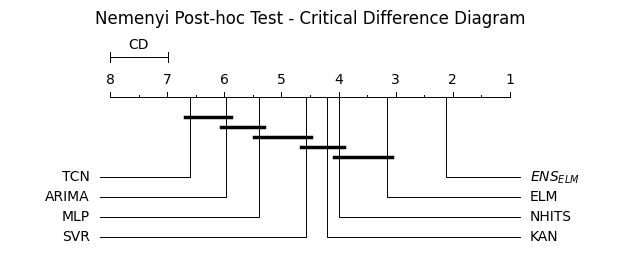


Ranks Médios:
             meanrank    median       mad  ci_lower  ci_upper effect_size  \
$ENS_{ELM}$  2.122222  0.860307  0.164032  0.612001   0.91588         0.0   
ELM          3.155556  0.875008  0.134486  0.622758   0.91241   -0.066111   
NHITS        3.988889  0.879226  0.134657  0.721324   0.91463   -0.085036   
KAN          4.200000  0.877168  0.145552  0.710629  0.918543   -0.073341   
SVR          4.577778  0.902139  0.181928  0.613833  0.990414   -0.162897   
MLP          5.388889  0.928938  0.209862  0.617845  0.987787   -0.245777   
ARIMA        5.966667  0.925404  0.281437  0.618043  1.086662    -0.19062   
TCN          6.600000  0.907079  0.168606  0.744729  0.996246   -0.189663   

              magnitude effect_size_above magnitude_above  
$ENS_{ELM}$  negligible               0.0      negligible  
ELM          negligible         -0.066111      negligible  
NHITS        negligible         -0.021142      negligible  
KAN          negligible          0.009901      negl

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from autorank import autorank, plot_stats
import numpy as np

# 1. Dados de exemplo (Substitua pelo seu DataFrame real)
# Cada coluna é um algoritmo, cada linha é um dataset/fold
data = df_all[models].copy()#[df_all['ts'].isin([
    #'austres',
   # 'milk',
    #'pollution',
    #'redwine',
    #'sunspot',
    #'temperature',
    #'ozon'
#])]#[models].copy()
data = data.rename(columns={
        'arima': 'ARIMA',
        'kan': 'KAN',
        'mlp': 'MLP',
        'nhits':"NHITS",
        'tcn': 'TCN',
        'svr': 'SVR',
        'scn': 'SCN',
        'elm': 'ELM',
       'mlpbagg': '$ENS_{MLP}$',
        'rf': '$ENS_{DT}$',
        'elmbagg': '$ENS_{ELM}$',
    }
    )
# 2. Executar o autorank
# Se os dados não forem normais, ele usará Friedman automaticamente.
# Se você quiser garantir o comportamento não-paramétrico, 
# o parâmetro correto para versões recentes é 'approach'.
result = autorank(
    data, alpha=0.1, verbose=False, 
    order='ascending', 
    approach='frequentist'
)

# 3. Gerar o gráfico de Diferença Crítica (CD Diagram)
# O autorank só gera o CD diagram se o teste de Friedman for significativo
if result.posthoc == 'nemenyi':
    plt.figure(figsize=(12, 5))
    plot_stats(result)
    plt.title("Nemenyi Post-hoc Test - Critical Difference Diagram")
    plt.savefig(f'nemenyi.pdf', format='pdf', bbox_inches='tight')
    plt.show()
else:
    print(f"O teste post-hoc detectado foi: {result.posthoc}")
    print("Para gerar o CD diagram, o autorank precisa detectar dados não-paramétricos.")
    # Forçando o plot mesmo assim (se disponível para o teste detectado)
    plot_stats(result)
   

    plt.show()

# 4. Ver os ranks médios calculados
print("\nRanks Médios:")
print(result.rankdf)

In [26]:
print(f"Valor da Diferença Crítica (CD): {result.cd}")


Valor da Diferença Crítica (CD): 1.0149752728828054


In [ ]:
# 1. O P-Value do teste global (Friedman)
print(f"P-value do Teste de Friedman: {result.pvalue}")

# 2. Ver se a diferença é significante (Comparando p-value com alpha)
is_significant = result.pvalue < 0.05
print(f"Existe diferença estatística global? {is_significant}")